# 1. Image Classification

## Simple Concept

Image classification means identifying what an image contains and assigning a class label to the entire image.

For example, if we provide a picture of a dog to a model, it predicts the label **Dog**.

## How It Works

**Input Image → CNN Model → Predicted Class**

Example:

- Input: An image containing a dog
- Model prediction: Dog
- Output: Dog

The model predicts the main class for the entire image. It does not tell us the exact location of the dog.

## Real-World Example

A photo application can automatically classify uploaded images into categories such as dogs, cats, cars, and flowers.

## Key Point

Image classification answers:

**“What is in this image?”**

It does not answer where an object is located.

In [1]:
import torch
import torch.nn as nn

# A simple classification model
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3 * 32 * 32, 3)
)

# One RGB image: 3 channels, 32 × 32 pixels
image = torch.randn(1, 3, 32, 32)

# Predict class scores
scores = model(image)

classes = ["Cat", "Dog", "Car"]

predicted_index = torch.argmax(scores, dim=1).item()

print("Predicted class:", classes[predicted_index])

Predicted class: Dog


Python explanation
- nn.Flatten() converts the image into a one-dimensional sequence of values.
- nn.Linear() produces three class scores: one for each class.
- torch.randn() creates a sample image tensor with the required shape.
- torch.argmax() selects the class with the highest score.
Note: This model has not been trained, so its prediction is random. It demonstrates the classification process, not accurate image recognition.

# 2. Multi-Class Classification

## Simple Concept

Multi-class classification means predicting one class from three or more possible classes.

For example, a model may classify an image as a **Cat, Dog, or Car**.

The model compares the scores for all available classes and selects the class with the highest score.

## How It Works

**Input Image → Model → Class Scores → Predicted Class**

Example:

- Cat score: 0.15
- Dog score: 0.75
- Car score: 0.10

Predicted class: **Dog**

These scores are illustrative. When scores are produced using softmax, they represent probabilities and sum to 1.

## Real-World Example

A wildlife monitoring system can classify images into different animal categories, such as tiger, elephant, deer, and lion.

## Key Point

Multi-class classification answers:

**“Which one class does this image belong to?”**

In standard multi-class classification, the model predicts one class for the entire image. It does not identify multiple object locations.

In [2]:
import torch

# Example class probabilities
probabilities = torch.tensor([0.15, 0.75, 0.10])

classes = ["Cat", "Dog", "Car"]

predicted_index = torch.argmax(probabilities).item()

print("Predicted class:", classes[predicted_index])
print("Confidence:", probabilities[predicted_index].item())

Predicted class: Dog
Confidence: 0.75


Python explanation
- torch.tensor() stores the scores for the three classes.
- torch.argmax() finds the index of the highest score.
- classes[predicted_index] retrieves the corresponding class label.
- probabilities[predicted_index] retrieves its probability, which is 75% in this example.
Remember the difference: Multi-class classification predicts one class for the whole image. Object detection can identify several objects in the same image, along with their locations.

# 3. Object Localization

## Simple Concept

Object localization means identifying an object in an image and finding its position using a bounding box.

Unlike image classification, localization tells us both **what the object is and where it is located**.

## How It Works

**Input Image → Model → Class Label + Bounding Box**

Example:

- Input: An image containing a dog
- Predicted class: Dog
- Bounding box: A rectangle around the dog

The bounding box identifies the region where the dog is located.

## Bounding Box Coordinates

A bounding box can be represented using four values:

- x: horizontal position
- y: vertical position
- width: box width
- height: box height

For example, `(50, 30, 120, 100)` means the box starts at position `(50, 30)`, has a width of 120 pixels, and a height of 100 pixels.

This example uses the format `(x, y, width, height)`.

## Real-World Example

A security camera system can locate a person in an image by drawing a rectangle around the person.

## Key Point

Object localization answers:

**“What is the object, and where is it located?”**

In a basic localization task, the model typically predicts one main object's location. Object detection extends this idea to multiple objects in the same image.

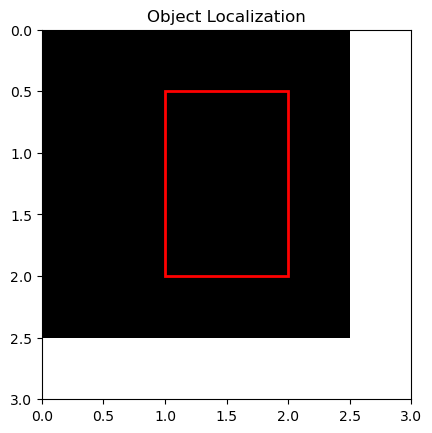

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Create a sample image
fig, ax = plt.subplots()

ax.imshow([[0, 0, 0], [0, 0, 0], [0, 0, 0]],
          cmap="gray")

# Bounding box: x, y, width, height
box = patches.Rectangle(
    (1, 0.5), 1, 1.5,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(box)
ax.set_title("Object Localization")
ax.set_xlim(0, 3)
ax.set_ylim(3, 0)
plt.show()

Python explanation
- patches.Rectangle() creates a rectangular bounding box.
- (1, 0.5) specifies the top-left position in the plot's coordinate system.
- 1 and 1.5 specify the width and height.
- ax.add_patch(box) draws the rectangle on the image.
This uses a simple sample image to demonstrate the box. No trained model or real object recognition is involved.

# 4. Object Detection

## Simple Concept

Object detection identifies multiple objects in an image and predicts the location of each object using a bounding box.

It also predicts a class label and a confidence score for each detected object.

## How It Works

**Image → Objects → Bounding Boxes + Classes + Confidence**

Example: An image contains two people and one car.

The model may predict:

- Person — Confidence: 0.95 — Bounding box around Person 1
- Person — Confidence: 0.89 — Bounding box around Person 2
- Car — Confidence: 0.92 — Bounding box around the car

These confidence values are illustrative, not actual model results.

## Main Components

- **Bounding box:** Shows where an object is located.
- **Class label:** Identifies the object, such as Person, Car, or Dog.
- **Confidence score:** Indicates how confident the model is about a prediction.

## Real-World Example

A traffic monitoring system detects cars, buses, motorcycles, and pedestrians in a single road image. Each detected object receives its own bounding box and class prediction.

## Key Point

Object detection answers:

**“What objects are present, and where is each object located?”**

Unlike basic image classification, object detection can identify multiple objects of different classes in the same image.


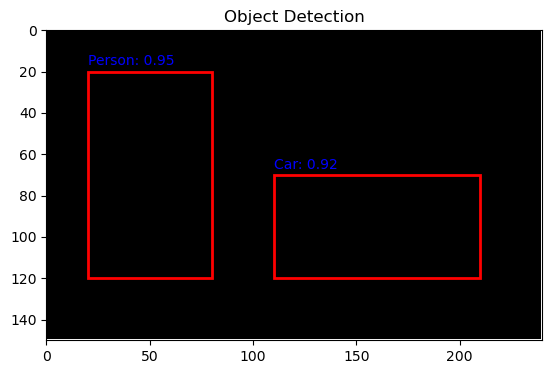

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Example detection results (illustrative)
detections = [
    {"label": "Person", "box": (20, 20, 60, 100), "confidence": 0.95},
    {"label": "Car", "box": (110, 70, 100, 50), "confidence": 0.92}
]

fig, ax = plt.subplots()

# Blank sample image
ax.imshow([[0] * 240 for _ in range(150)], cmap="gray")

for item in detections:
    x, y, width, height = item["box"]

    box = patches.Rectangle(
        (x, y), width, height,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(box)
    ax.text(
        x, y - 3,
        f'{item["label"]}: {item["confidence"]:.2f}',
        color="blue"
    )

ax.set_xlim(0, 240)
ax.set_ylim(150, 0)
ax.set_title("Object Detection")
plt.show()

Python explanation
- detections stores the example labels, bounding boxes, and confidence scores.
- box contains the position and size of each rectangle.
- patches.Rectangle() draws a separate bounding box for each object.
- ax.text() displays the class label and confidence score.
This example visualizes predefined detections. It does not use a trained model to detect real objects.
Remember: Object detection combines classification and localization for multiple objects.

# 5. Image Segmentation

## Simple Concept

Image segmentation means dividing an image into meaningful regions by assigning a label to each pixel.

Unlike object detection, which draws rectangular bounding boxes around objects, segmentation can identify the actual shape and boundaries of objects.

## How It Works

**Input Image → Segmentation Model → Pixel-Level Labels**

Example: An image contains a person standing on grass.

The model can label:
- Person pixels as Person
- Grass pixels as Grass
- Sky pixels as Sky

## Types of Image Segmentation

**1. Semantic Segmentation**

Assigns a class label to every pixel. Objects belonging to the same class receive the same label, even when they are separate objects.

Example: Two different cars are both labeled Car.

**2. Instance Segmentation**

Identifies each individual object separately and outlines its pixel-level shape.

Example: Two cars are identified as Car 1 and Car 2, with separate masks.

## Object Detection vs Image Segmentation

- Object detection: Draws a rectangle around an object.
- Image segmentation: Identifies the pixels belonging to an object or region.

## Real-World Example

In medical imaging, segmentation can identify the exact region of a tumor rather than just drawing a rectangle around it.

## Key Point

Image segmentation answers:

**“Which pixels belong to which object or region?”**

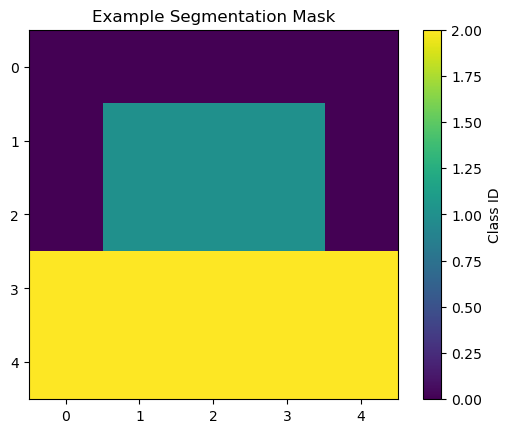

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Example image labels:
# 0 = Background, 1 = Person, 2 = Grass
segmentation_mask = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 1, 0],
    [2, 2, 2, 2, 2],
    [2, 2, 2, 2, 2]
])

plt.imshow(segmentation_mask, cmap="viridis")
plt.title("Example Segmentation Mask")
plt.colorbar(label="Class ID")
plt.show()

Python explanation
- np.array() creates a small segmentation mask.
- Each number represents a class assigned to a pixel.
- plt.imshow() displays the pixel-level labels as an image.
- The color bar shows the numeric class IDs.
This is a manually created example mask, not a model prediction.
Remember: Classification labels an image, localization finds an object's position, detection finds multiple objects with boxes, and segmentation identifies pixel-level regions.

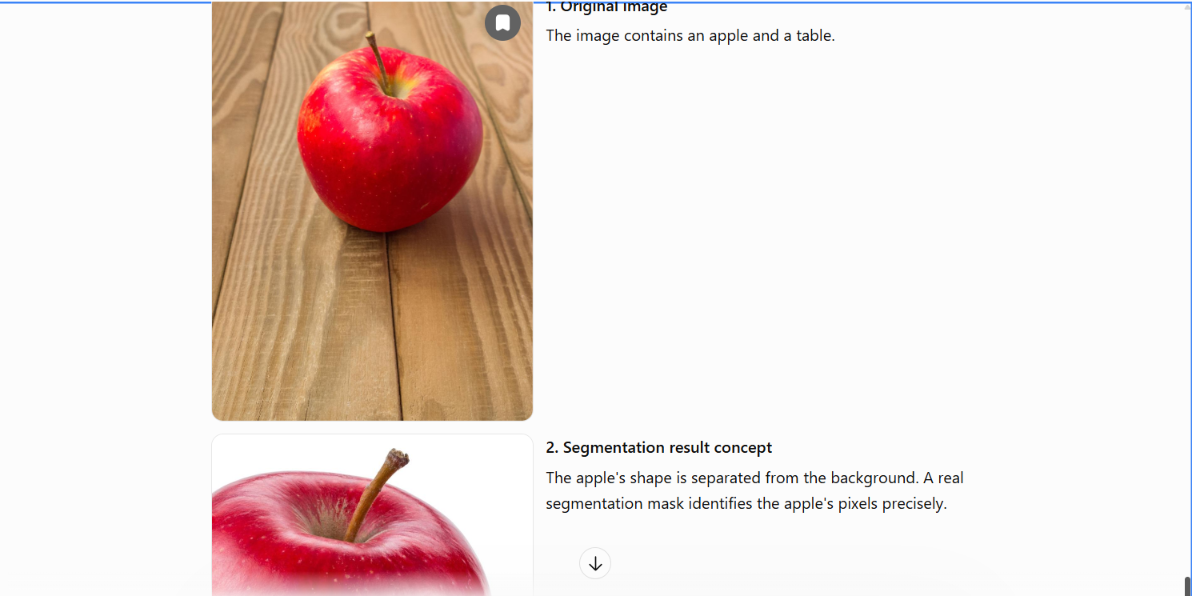

# 6. Bounding Boxes

## Simple Concept

A bounding box is a rectangle drawn around an object in an image to show its location and size.

Object detection models use bounding boxes to identify where each detected object is located.

## How It Works

**Image → Detect Object → Draw Bounding Box**

For example, if an image contains a dog, the model draws a rectangle around the dog.

## Bounding Box Coordinates

A common bounding box format is:

- **x:** Horizontal position of the top-left corner.
- **y:** Vertical position of the top-left corner.
- **width:** Width of the rectangle.
- **height:** Height of the rectangle.

Example: `(50, 30, 120, 100)`

This means:
- The box starts 50 pixels from the left.
- The box starts 30 pixels from the top.
- The box is 120 pixels wide.
- The box is 100 pixels high.

Other models use formats such as `(x_min, y_min, x_max, y_max)`, which represent the top-left and bottom-right corners. Always check which format the model expects.

## Real-World Example

In a traffic camera, a bounding box can surround each car, bus, or pedestrian so the system can locate them in the image.

## Key Point

A bounding box tells us **where an object is and how much image space it occupies**. It does not describe the object's exact shape.

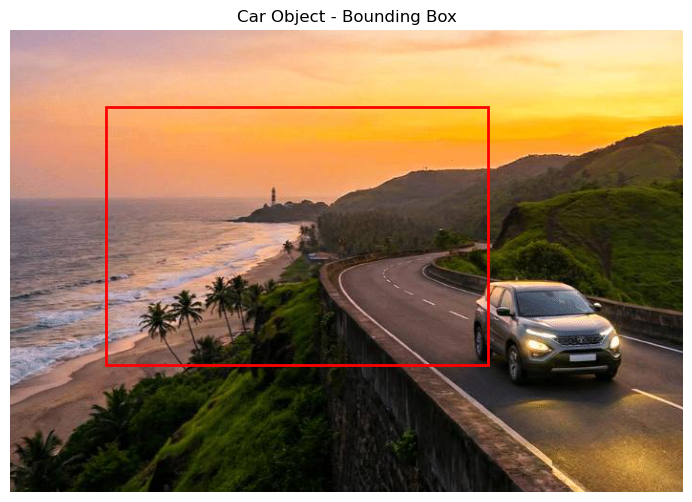

In [9]:

from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Load your local car image
image_path = r"C:\Users\nanda\OneDrive\Pictures\Image\car.jpg"
image = Image.open(image_path).convert("RGB")

# Display the real image
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(image)

# Bounding box coordinates (adjust these to fit your car)
x_min = 100
y_min = 80
x_max = 500
y_max = 350

# Draw bounding box around the car
box = patches.Rectangle(
    (x_min, y_min),
    x_max - x_min,
    y_max - y_min,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(box)
ax.set_title("Car Object - Bounding Box")
ax.axis("off")

plt.show()


# 7. Bounding Box Coordinates

## Simple Concept

Bounding box coordinates tell us the exact position and size of an object in an image.

Images use a coordinate system to locate pixels.

- **X-coordinate:** Measures position from the left.
- **Y-coordinate:** Measures position from the top.
- **X-min and Y-min:** Represent the top-left corner of a bounding box.
- **X-max and Y-max:** Represent the bottom-right corner of a bounding box.

## Example

Suppose a car has these bounding box coordinates:

`(100, 80, 500, 350)`

Using the format `(x_min, y_min, x_max, y_max)`:

- Left edge: 100
- Top edge: 80
- Right edge: 500
- Bottom edge: 350
- Width: 400 pixels
- Height: 270 pixels

## Important Point

Image coordinates usually start at the **top-left corner `(0, 0)`**. The X-coordinate increases toward the right, and the Y-coordinate increases toward the bottom.

Different object detection models may use different coordinate formats. Always check the expected format.

## Real-World Example

A traffic camera detects a car and predicts its bounding box coordinates. These coordinates tell the system where to draw a rectangle around the car.

Image width: 705
Image height: 484
Bounding box width: 400
Bounding box height: 270


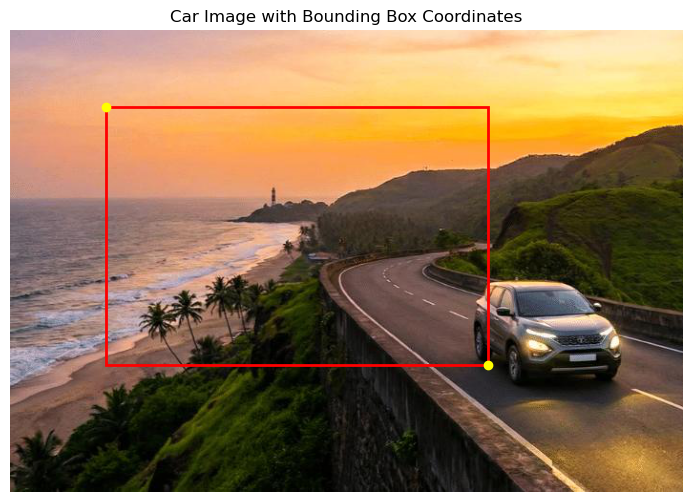

In [10]:

from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image_path = r"C:\Users\nanda\OneDrive\Pictures\Image\car.jpg"
image = Image.open(image_path).convert("RGB")

# Check image dimensions
image_width, image_height = image.size
print("Image width:", image_width)
print("Image height:", image_height)

# Example bounding box coordinates
x_min = 100
y_min = 80
x_max = min(500, image_width)
y_max = min(350, image_height)

# Calculate box dimensions
box_width = x_max - x_min
box_height = y_max - y_min

print("Bounding box width:", box_width)
print("Bounding box height:", box_height)

# Display the real image and bounding box
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(image)

box = patches.Rectangle(
    (x_min, y_min),
    box_width,
    box_height,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(box)
ax.scatter([x_min, x_max], [y_min, y_max], color="yellow")
ax.set_title("Car Image with Bounding Box Coordinates")
ax.axis("off")
plt.show()


Python explanation
- image.size retrieves the image width and height.
- x_min, y_min, x_max, and y_max define the rectangle's corners.
- Subtracting the minimum coordinates from the maximum coordinates calculates the box width and height.
- ax.scatter() marks the two opposite corners in yellow.
- The red rectangle shows the bounding box on your actual car photograph.
Note: These are example coordinates. Adjust them to fit your car. The code draws a box but does not detect the car automatically.

# 8. Class Labels

## Simple Concept

A class label tells us what an object detected in an image is.

For example, an object detection model may identify objects as Car, Person, Dog, Bus, or Bicycle.

Each detected object receives a predicted class label.

## How It Works

**Image → Object Detection Model → Bounding Box + Class Label**

Example:
- Object 1: Car
- Object 2: Person
- Object 3: Bicycle

Each label identifies the object inside its corresponding bounding box.

## Class IDs

Models sometimes represent class labels using numbers called class IDs.

Example:

- 0 → Person
- 1 → Car
- 2 → Bicycle
- 3 → Dog

These IDs are illustrative. The actual mapping depends on the dataset or model.

## Real-World Example

A traffic monitoring system detects a car and a motorcycle in the same image. It assigns the label `Car` to one bounding box and `Motorcycle` to the other.

## Key Point

A bounding box tells us **where the object is**, while a class label tells us **what the object is**.

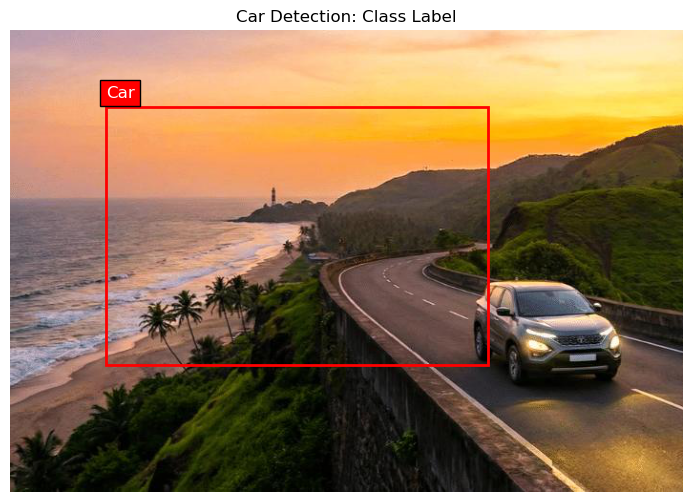

In [11]:

from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image_path = r"C:\Users\nanda\OneDrive\Pictures\Image\car.jpg"
image = Image.open(image_path).convert("RGB")

image_width, image_height = image.size

# Example bounding box coordinates
x_min = 100
y_min = 80
x_max = min(500, image_width)
y_max = min(350, image_height)

# Example class label
class_label = "Car"

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(image)

box = patches.Rectangle(
    (x_min, y_min),
    x_max - x_min,
    y_max - y_min,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(box)

ax.text(
    x_min,
    max(0, y_min - 10),
    class_label,
    color="white",
    fontsize=12,
    bbox=dict(facecolor="red", pad=4)
)

ax.set_title("Car Detection: Class Label")
ax.axis("off")
plt.show()


Python explanation
- class_label = "Car" defines the object's label.
- patches.Rectangle() draws the bounding box.
- ax.text() displays the label above the box.
- bbox gives the label a red background so it is easy to read.
Important: The code manually assigns the label Car. It does not recognize the car automatically. Also, adjust the coordinates to fit your image.

# 9. Confidence Score

## Simple Concept

A confidence score indicates how confident an object detection model is about a prediction.

For example, when a model detects a car, it might assign a confidence score of `0.95`.

This means the model has a high confidence in that prediction, according to its scoring method.

## How It Works

**Image → Detection Model → Class Label + Bounding Box + Confidence Score**

Example:

| Detected Object | Confidence Score |
|---|---:|
| Car | 0.95 |
| Person | 0.87 |
| Bicycle | 0.62 |

These values are illustrative.

- A higher score generally indicates stronger confidence.
- A lower score indicates less confidence in the prediction.
- A confidence threshold can be used to filter out predictions with scores below a chosen value.

For example, with a threshold of `0.70`, the bicycle prediction with a score of `0.62` would be filtered out.

## Real-World Example

A traffic monitoring system detects cars on a road. It may keep predictions with confidence scores above a selected threshold to reduce uncertain detections.

## Key Point

**Confidence score tells us how strongly a model supports a prediction.**

It is not necessarily the true probability that the prediction is correct. Its interpretation depends on the model and how its scores are produced.

Detection displayed


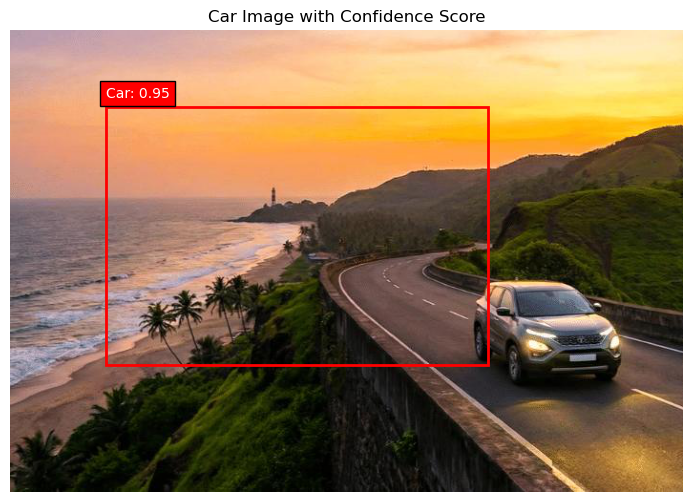

In [12]:

from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image_path = r"C:\Users\nanda\OneDrive\Pictures\Image\car.jpg"
image = Image.open(image_path).convert("RGB")

image_width, image_height = image.size

# Example bounding box coordinates
x_min = 100
y_min = 80
x_max = min(500, image_width)
y_max = min(350, image_height)

# Example detection information
class_label = "Car"
confidence = 0.95
threshold = 0.70

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(image)

if confidence >= threshold:
    box = patches.Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )
    ax.add_patch(box)

    ax.text(
        x_min,
        max(0, y_min - 10),
        f"{class_label}: {confidence:.2f}",
        color="white",
        bbox=dict(facecolor="red", pad=4)
    )

    print("Detection displayed")
else:
    print("Detection filtered out")

ax.set_title("Car Image with Confidence Score")
ax.axis("off")
plt.show()


Python explanation
- confidence = 0.95 sets an example score of 95%.
- threshold = 0.70 sets the minimum score for displaying the prediction.
- if confidence >= threshold checks whether the prediction passes the threshold.
- f"{class_label}: {confidence:.2f}" displays the label and score.
Important: The score is manually entered. A real trained model would produce its own prediction scores.

# 10. Intersection over Union (IoU)

## Simple Concept

Intersection over Union (IoU) measures how much a predicted bounding box overlaps with the actual bounding box of an object.

It helps us understand how accurately a model has located an object.

## How It Works

**IoU = Overlapping Area ÷ Combined Area**

- **Intersection:** The area shared by the predicted box and the actual box.
- **Union:** The total area covered by both boxes, counting their shared area only once.

IoU ranges from 0 to 1.

- **IoU = 0:** The boxes do not overlap.
- **IoU = 0.5:** The boxes have a moderate overlap.
- **IoU = 1:** Both boxes match perfectly.

## Example

Suppose a model predicts a bounding box around a car. We compare it with the correct, manually labeled box.

- Actual box: The correct car location.
- Predicted box: The location estimated by the model.
- IoU: A score measuring their overlap.

A higher IoU generally means the predicted box matches the actual box more closely.

## Real-World Example

When evaluating a car detection model, IoU helps measure whether its predicted rectangle closely matches the rectangle labeled by a human.

## Key Point

**Confidence score measures confidence in a prediction; IoU measures overlap between two boxes.**

IoU is commonly used to evaluate localization accuracy and help decide whether a detection matches a ground-truth object.

IoU: 0.610


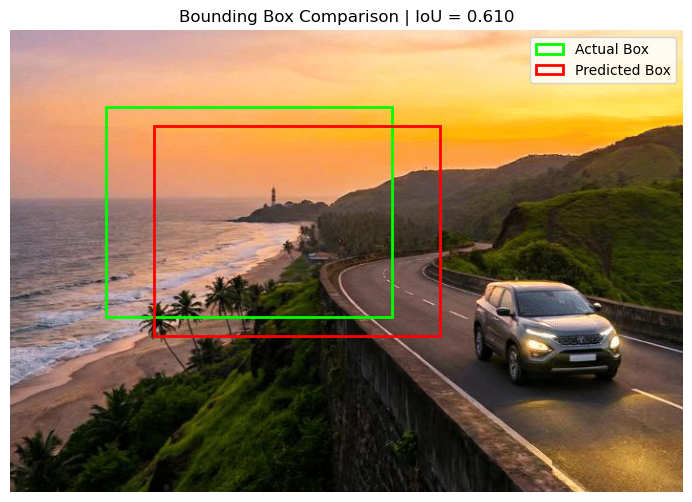

In [13]:

from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

image_path = r"C:\Users\nanda\OneDrive\Pictures\Image\car.jpg"
image = Image.open(image_path).convert("RGB")

# Format: (x_min, y_min, x_max, y_max)
actual_box = (100, 80, 400, 300)
predicted_box = (150, 100, 450, 320)

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

iou = calculate_iou(actual_box, predicted_box)
print(f"IoU: {iou:.3f}")

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(image)

for box, color, label in [
    (actual_box, "lime", "Actual Box"),
    (predicted_box, "red", "Predicted Box")
]:
    x1, y1, x2, y2 = box
    rectangle = patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        linewidth=2, edgecolor=color,
        facecolor="none", label=label
    )
    ax.add_patch(rectangle)

ax.set_title(f"Bounding Box Comparison | IoU = {iou:.3f}")
ax.legend()
ax.axis("off")
plt.show()


Python explanation
- actual_box represents the human-labeled reference box.
- predicted_box represents an example model prediction.
- intersection calculates the shared area.
- union calculates the combined area without double-counting.
- calculate_iou() divides the intersection by the union.
Important: These example boxes are not automatically fitted to the car, so the calculated IoU only compares the supplied coordinates. To evaluate a real detector, use a correctly labeled box and the model's actual prediction.

# 11. Non-Maximum Suppression (NMS)

## Simple Concept

Non-Maximum Suppression (NMS) is a technique used in object detection to remove duplicate bounding boxes around the same object.

Sometimes, a model predicts several overlapping boxes around one car. NMS keeps the strongest prediction and removes other boxes that overlap too much with it.

## How It Works

**Multiple Bounding Boxes → Compare Confidence Scores and IoU → Keep the Best Boxes**

Example: A model predicts three boxes around the same car.

- Box A — Confidence: 0.95
- Box B — Confidence: 0.87
- Box C — Confidence: 0.72

If these boxes overlap sufficiently, NMS keeps Box A and suppresses the other overlapping boxes.

NMS uses an IoU threshold to determine whether boxes overlap too much. The exact result depends on the chosen threshold and the class of each detection.

## Real-World Example

A traffic camera detects one car but produces three overlapping rectangles around it. NMS reduces these duplicate predictions so the final output can show one main bounding box for that car.

## Key Point

**NMS reduces duplicate detections.**

It does not train the model or improve the original predicted coordinates. It filters predictions after detection.

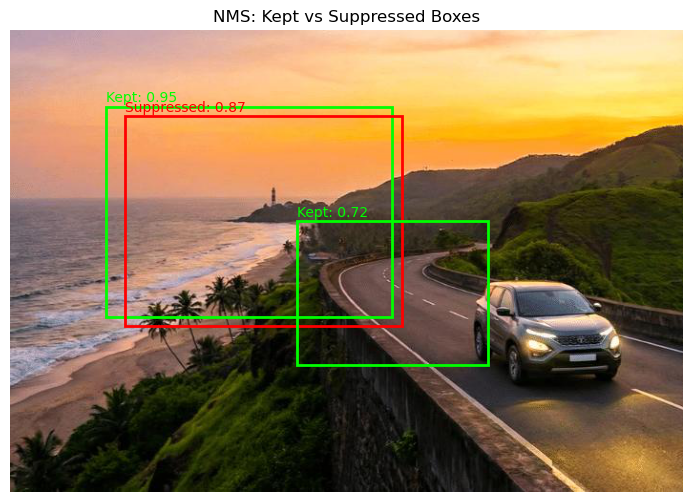

Kept box indices: [0, 2]


In [14]:

from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
from torchvision.ops import nms

image_path = r"C:\Users\nanda\OneDrive\Pictures\Image\car.jpg"
image = Image.open(image_path).convert("RGB")

# Example boxes: (x_min, y_min, x_max, y_max)
boxes = torch.tensor([
    [100, 80, 400, 300],
    [120, 90, 410, 310],
    [300, 200, 500, 350]
], dtype=torch.float32)

# Example confidence scores
scores = torch.tensor([0.95, 0.87, 0.72])

# Remove highly overlapping boxes
keep = nms(boxes, scores, iou_threshold=0.5)

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(image)

for i in range(len(boxes)):
    x1, y1, x2, y2 = boxes[i].tolist()

    if i in keep.tolist():
        color = "lime"
        label = f"Kept: {scores[i]:.2f}"
    else:
        color = "red"
        label = f"Suppressed: {scores[i]:.2f}"

    rect = patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        linewidth=2, edgecolor=color,
        facecolor="none"
    )
    ax.add_patch(rect)
    ax.text(x1, max(0, y1 - 5), label, color=color)

ax.set_title("NMS: Kept vs Suppressed Boxes")
ax.axis("off")
plt.show()

print("Kept box indices:", keep.tolist())


Python explanation
- boxes contains three example bounding boxes.
- scores contains their confidence scores.
- nms() compares boxes using IoU and ranks them by confidence.
- iou_threshold=0.5 sets the overlap threshold used for suppression.
- Green boxes are kept; red boxes are suppressed.
Important: This requires torchvision to be installed. The example coordinates must be adjusted to your image, and the third box may remain if its overlap with the best box is below the threshold.